# Tutorial 08 — Visibility-domain forward model (ALMA uv data)

This tutorial shows how to take a **parametric RADJAX disk model**, render it to an
image cube, and push it through the **visibility-domain forward model**
(`radjax.core.vis_forward_model`) onto the **real uv sampling of an ALMA/MAPS
measurement set** — exactly what you need to fit disk models directly in the uv plane.

We use HD 163296 CO 2–1 (MAPS). Along the way we produce:

1. the **uv sampling pattern** of the MS, colour-coded by visibility **weight**;
2. **clean model images** (the rendered cube);
3. the model's **Fourier plane before vs after** uv sampling;
4. the **dirty image** of the sampled model;
5. a **model-vs-data visibility comparison** (amplitude vs uv-distance, gridded |V|);
6. a **model-vs-data dirty-image comparison** + the pointwise-average χ².

**Conventions.** Image cube in **Jy/pixel**; `uvw` in **metres**; `freq` in **Hz**;
the NUFFT maps image → visibilities with the phase centre at pixel `(N//2, N//2)`.
`image_to_vis` runs on JAX's default device — the **GPU** if a CUDA-enabled
`jax-finufft` build is installed, otherwise the CPU — and is fully differentiable.

> `visibilities.py` is deprecated; this tutorial uses `vis_forward_model.py` throughout.

## 0. Installation — GPU `jax-finufft` (optional)

The uv forward model (`image_to_vis`) uses [`jax-finufft`](https://github.com/flatironinstitute/jax-finufft).
**The PyPI wheel is CPU-only** — everything below still runs, just on the CPU. To run the
NUFFT on the **GPU** (recommended for fitting) you need a CUDA-enabled build. If you already
have a working radjax environment (pip-installed JAX + CUDA), build `jax-finufft` from source
**into that same env** — do *not* `conda install` the conda-forge GPU build, which pulls a
conda JAX/jaxlib that can clash with your pip stack.

**0. Find your GPU's compute capability** (sets the CUDA arch):
```bash
nvidia-smi --query-gpu=compute_cap --format=csv,noheader
# 12.0 -> arch 120 (Blackwell) · 9.0 -> 90 (Hopper) · 8.0 -> 80 (Ampere)
```

**1. A CUDA toolchain that can target your GPU** (Blackwell/sm_120 needs CUDA ≥ 12.8). The
system toolkit is often too old or rejects your host gcc, so use a throwaway conda toolchain:
```bash
conda create -y -p /tmp/jfbuild -c nvidia -c conda-forge \
    cuda-nvcc=12.9 cuda-cudart-dev=12.9 cuda-cccl=12.9 libcufft-dev \
    cuda-nvrtc-dev=12.9 cuda-driver-dev=12.9
```

**2. Clone with submodules** (the vendored FINUFFT is a git submodule — easy to miss):
```bash
git clone --recurse-submodules https://github.com/flatironinstitute/jax-finufft
cd jax-finufft    # if you forgot: git submodule update --init --recursive
```

**3. Build a GPU wheel** (replace `120` with your arch from step 0):
```bash
PREFIX=/tmp/jfbuild
pip wheel . --no-deps -w dist \
  --config-settings=cmake.define.JAX_FINUFFT_USE_CUDA=ON \
  --config-settings=cmake.define.CMAKE_CUDA_COMPILER=$PREFIX/bin/nvcc \
  --config-settings=cmake.define.CMAKE_CUDA_HOST_COMPILER=/usr/bin/g++ \
  --config-settings=cmake.define.CMAKE_CUDA_ARCHITECTURES=120 \
  --config-settings=cmake.define.CUDAToolkit_ROOT=$PREFIX \
  --config-settings=cmake.define.FINUFFT_FFTW_LIBRARIES=DOWNLOAD
```
(`FINUFFT_FFTW_LIBRARIES=DOWNLOAD` makes FINUFFT fetch + build its own FFTW, sidestepping
broken system-FFTW detection.)

**4. Install into your radjax env** (same version as the CPU wheel — radjax code is unchanged):
```bash
pip install --force-reinstall --no-deps dist/jax_finufft-*.whl
```

**5. Point the GPU extension at your pip CUDA libs.** The wheel has no RPATH, so without this
`jax_finufft_gpu.so` fails to load and JAX silently falls back to CPU (the tell-tale error is
*"MLIR translation rule for primitive 'nufft2' not found for platform cuda"*):
```bash
SP=$(python -c "import site; print(site.getsitepackages()[0])")
patchelf --set-rpath "$SP/nvidia/cufft/lib:$SP/nvidia/cuda_runtime/lib" \
    "$SP"/jax_finufft/jax_finufft_gpu*.so
```

**6. Verify, then clean up:**
```bash
python -c "import jax_finufft.jax_finufft_gpu; print('GPU jax-finufft OK')"
rm -rf /tmp/jfbuild      # the installed .so links your pip CUDA libs, not the toolchain
```
**Rollback to CPU-only:** `pip install --force-reinstall jax-finufft==1.3.1`.

*Simpler alternative (fresh env only):* conda-forge ships a prebuilt GPU build via
`mamba install -c conda-forge 'jax-finufft=*=cuda*'`, but it brings its own conda JAX/jaxlib —
fine for a brand-new env, risky to drop into an existing pip-based radjax env.

## 1. Setup

This tutorial targets **this repository's** `radjax` (radjax-public). The cell below puts the
repo root at the front of `sys.path` so `import radjax` resolves to it rather than any
pip-installed copy — important because the renderer's **velocity/rotation (Doppler)
convention** must match the package the tutorial was written for; a different install can
flip the model in velocity (and so flip the model dirty image). The printed `radjax:` path
should point inside this repo.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Use THIS repo's radjax, not whatever happens to be pip-installed (e.g. a dev checkout).
_repo = os.path.abspath("..")                       # notebook lives in <repo>/tutorials/
if os.path.isdir(os.path.join(_repo, "radjax")):
    sys.path.insert(0, _repo)

import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)           # visibilities are complex128

import radjax
from radjax.core.casa_io import read_ms, VisibilityData
from radjax.core.vis_forward_model import image_to_vis, chi2_vis, _dirty_image
from radjax.core import sensor, chemistry as chem
from radjax.models.broken_power_law import disk_from_yaml, forward_model_with_rays

C   = 2.99792458e8      # speed of light [m/s]
NU0 = 230538e6          # CO 2-1 rest frequency [Hz]

print("radjax:", radjax.__file__)                   # should be inside radjax-public
print("jax devices:", [d.platform for d in jax.devices()])

radjax: /nfs/rhea.dgp/u8/d/len/code/radjax-public/radjax/__init__.py


jax devices: ['gpu', 'gpu']


## 2. Load the MAPS measurement set (uv data)

`read_ms` returns a `VisibilityData` with `uvw` (m), `freq` (Hz), complex `data`
(Jy), `weight`, and `flag`. We subsample channels to keep the tutorial fast.

> Set `MS` to your own MAPS measurement set.

In [2]:
# --- paths (edit MS to your local MAPS MS) ---
REPO   = os.path.abspath("..")       # this notebook lives in tutorials/
PARAMS = os.path.join(REPO, "data/HD163296/Flaherty/HD163296_CO_highres_cen.cm.params.yaml")
MS     = "/scratch/ondemand28/len/data/radjax/MAPS_uv/HD_163296_CO_220GHz_custom_0.1kms.bin_30s.ms.cvel"

vis_obs = read_ms(MS)
print(f"{vis_obs.nrows} rows x {vis_obs.nchan} channels")

STRIDE = 10
idx = np.arange(0, vis_obs.nchan, STRIDE)
vis = VisibilityData(uvw=vis_obs.uvw, data=vis_obs.data[:, idx], weight=vis_obs.weight[:, idx],
                     freq=vis_obs.freq[idx], flag=vis_obs.flag[:, idx])
print(f"using {vis.nrows} rows x {vis.nchan} channels (stride {STRIDE})")

374760 rows x 315 channels
using 374760 rows x 32 channels (stride 10)


### Imaging grid from the uv coverage

The field of view is set by the shortest baseline and the resolution by the longest,
so we derive a pixel size `dpix` and a power-of-two `npix` directly from the MS.

In [3]:
lam  = C / vis.freq                                   # (nchan,) [m]
uvd  = np.sqrt((vis.uvw[:, 0:1]/lam)**2 + (vis.uvw[:, 1:2]/lam)**2)   # (nrows,nchan) [lambda]
jlo, jhi = np.argmin(vis.freq), np.argmax(vis.freq)
Bmin = uvd[uvd[:, jlo] > 0, jlo].min()
Bmax = uvd[:, jhi].max()
npix = int(2 ** np.ceil(np.log2(np.ceil((1.0/Bmin)/(1.0/Bmax) * 2))))
dpix_as  = (np.degrees(1.0/Bmin) * 3600) / npix
dpix_rad = np.radians(dpix_as / 3600)
print(f"grid npix={npix}, dpix={dpix_as*1e3:.1f} mas, FOV={npix*dpix_as:.2f}\"")

grid npix=512, dpix=36.1 mas, FOV=18.49"

## 3. uv sampling pattern, colour-coded by weight

With millions of (u,v) points a raw scatter plot is slow and overplotted. We use
`hexbin`, which bins the points on a hexagonal grid in C — fast and readable. Left:
**sample density**; right: **summed weight** per cell (the effective sensitivity map).
We add the Hermitian conjugates (−u,−v) since a real sky makes the uv plane symmetric.

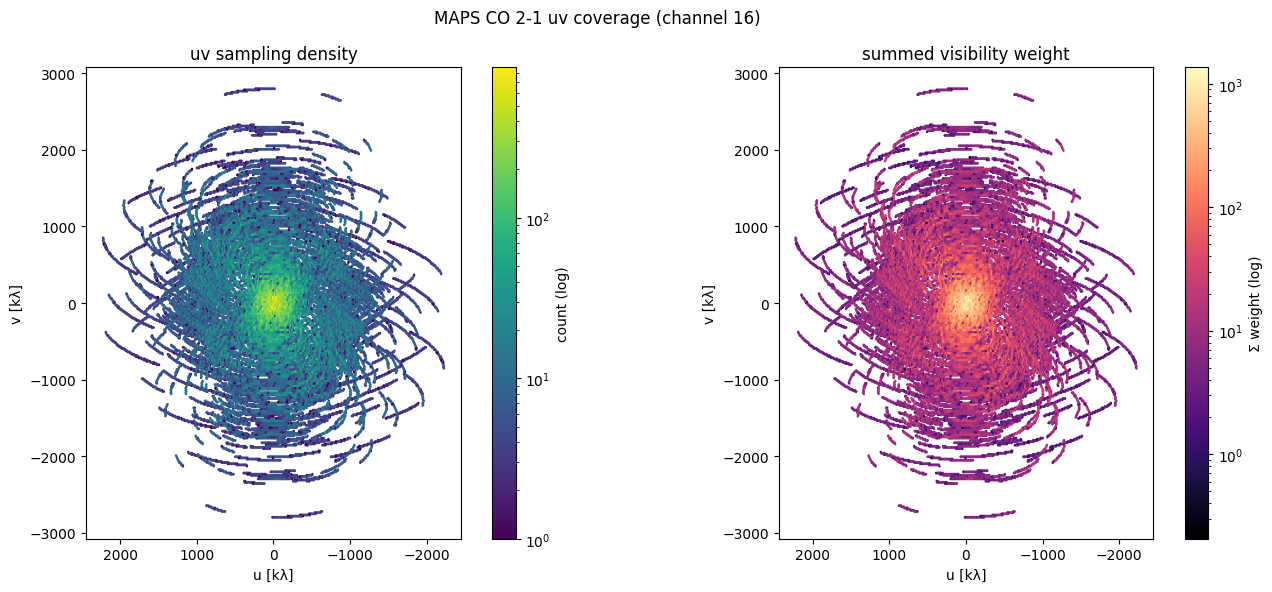

In [4]:
cc_cov = vis.nchan // 2                               # one representative channel
good   = ~np.asarray(vis.flag[:, cc_cov])
u_k = (vis.uvw[good, 0] / lam[cc_cov]) / 1e3         # [klambda]
v_k = (vis.uvw[good, 1] / lam[cc_cov]) / 1e3
w   = np.asarray(vis.weight[good, cc_cov])
# Hermitian conjugate for a symmetric picture
u_all = np.concatenate([u_k, -u_k]); v_all = np.concatenate([v_k, -v_k])
w_all = np.concatenate([w, w])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
hb0 = ax[0].hexbin(u_all, v_all, gridsize=320, bins='log', cmap='viridis', mincnt=1)
ax[0].set_title("uv sampling density"); plt.colorbar(hb0, ax=ax[0], label="count (log)")
hb1 = ax[1].hexbin(u_all, v_all, C=w_all, reduce_C_function=np.sum, gridsize=320,
                   bins='log', cmap='magma', mincnt=1)
ax[1].set_title("summed visibility weight"); plt.colorbar(hb1, ax=ax[1], label="Σ weight (log)")
for a in ax:
    a.set(xlabel="u [kλ]", ylabel="v [kλ]", aspect="equal"); a.invert_xaxis()
fig.suptitle(f"MAPS CO 2-1 uv coverage (channel {cc_cov})"); fig.tight_layout(); plt.show()

## 4. Build and render the parametric HD 163296 model

We load the Flaherty parametric disk + chemistry + observation config, build rays on a
render grid, and render the clean spectral cube in **Jy/pixel**.

In [5]:
disk_params = disk_from_yaml(PARAMS)
chem_params = chem.chemistry_from_yaml_path(PARAMS)
mol         = chem.load_molecular_tables(chem_params)
obs_params  = sensor.params_from_yaml(PARAMS)
vlsr        = float(obs_params.vlsr)

NPR  = 256                                   # render grid (pixels)
half = NPR * dpix_as / 2
xax  = np.linspace( half, -half, NPR)        # East to the left
yax  = np.linspace(-half,  half, NPR)
x_sky, y_sky = np.meshgrid(xax, yax, indexing="xy")

f_rf = vis.freq + NU0 * vlsr / C             # shift channels to the model rest frame
rays = sensor.rays_from_params(obs_params, jnp.array(x_sky), jnp.array(y_sky))
cube = forward_model_with_rays(disk_params=disk_params, chem_params=chem_params,
                               mol=mol, rays=rays, freqs=jnp.array(f_rf))
cube_np = np.asarray(cube)
cc = int(np.argmax(cube_np.sum(axis=(1, 2))))   # line-centre channel (most flux)
print(f"cube {cube_np.shape}, peak={cube_np.max():.4f} Jy/pix, line-centre channel={cc}")

cube (32, 256, 256), peak=0.0240 Jy/pix, line-centre channel=17


### Clean model images

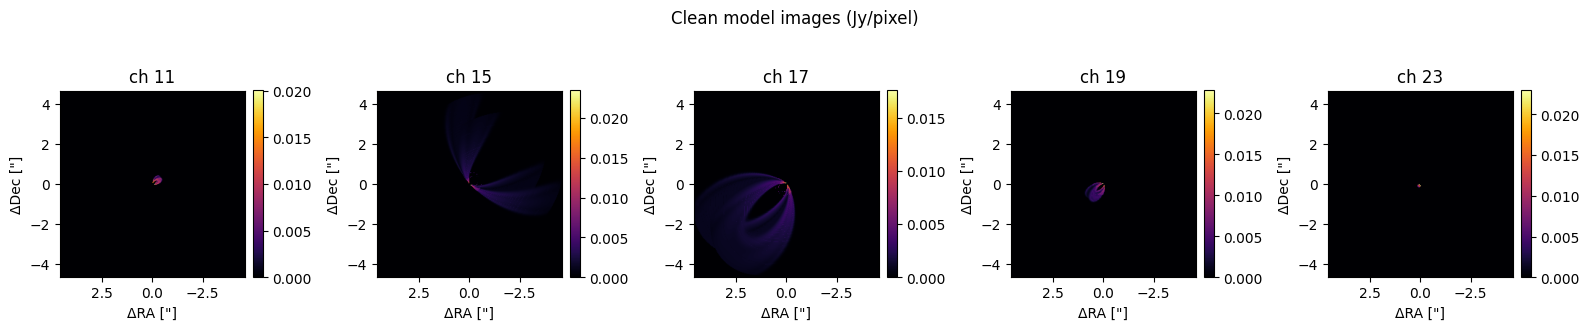

In [6]:
chans = np.unique(np.clip([cc-6, cc-2, cc, cc+2, cc+6], 0, vis.nchan-1))
ext = [half, -half, -half, half]
fig, ax = plt.subplots(1, len(chans), figsize=(3.2*len(chans), 3.4))
for a, ch in zip(np.atleast_1d(ax), chans):
    im = a.imshow(cube_np[ch], origin="lower", extent=ext, cmap="inferno")
    a.set_title(f"ch {ch}"); a.set(xlabel="ΔRA [\"]", ylabel="ΔDec [\"]")
    plt.colorbar(im, ax=a, fraction=0.046, pad=0.04)
fig.suptitle("Clean model images (Jy/pixel)"); fig.tight_layout(); plt.show()

## 5. Forward model: image cube → model visibilities

`image_to_vis` evaluates the continuous Fourier transform of the model image at each
observed baseline (NUFFT, type-2). This is the differentiable forward operator used for
uv-domain fitting.

In [7]:
import time
t0 = time.time()
vis_model = np.asarray(image_to_vis(cube_np, vis.uvw, vis.freq, dpix_rad))
print(f"image_to_vis: {time.time()-t0:.2f}s  ->  vis_model {vis_model.shape} (rows x chans)")

image_to_vis: 0.67s  ->  vis_model (374760, 32) (rows x chans)


## 6. The model's Fourier plane: before vs after uv sampling

**Before:** the dense 2-D FFT of the model image — the model's full visibility function
at every spatial frequency up to the pixel Nyquist. **After:** the same visibility
function evaluated only where the MS actually has baselines (the model visibilities,
gridded for display). The holes are exactly what the uv coverage above does *not* measure.

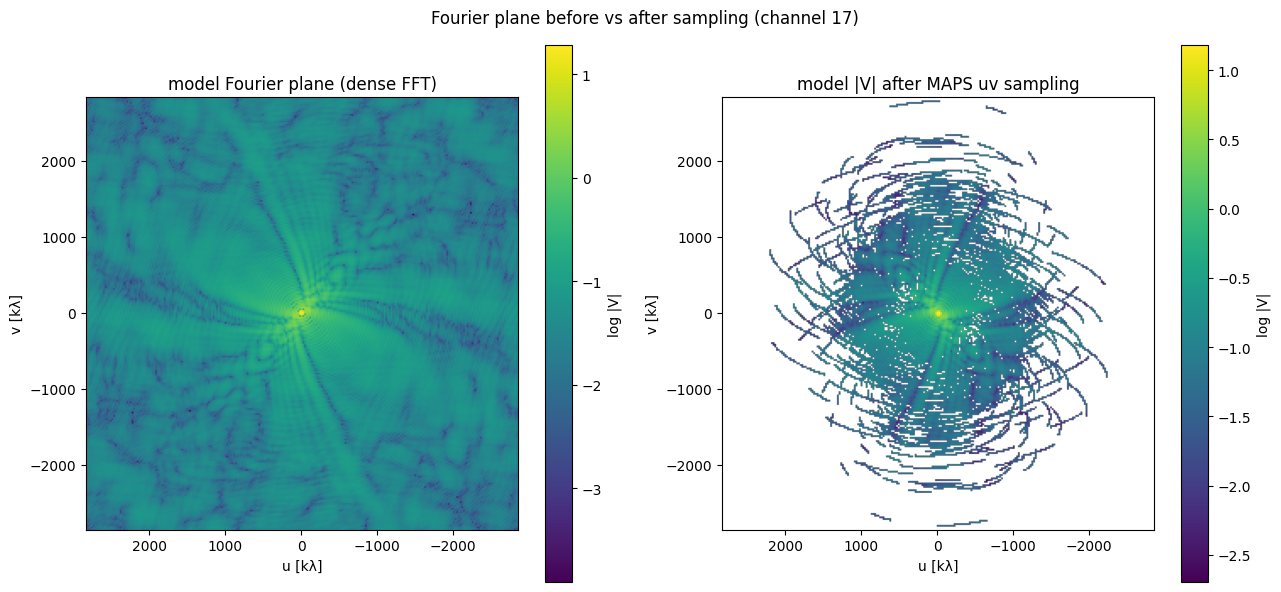

In [8]:
img = cube_np[cc]
ft  = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(img)))     # dense model Fourier plane
du  = 1.0 / (NPR * dpix_rad) / 1e3                             # uv cell [klambda]
uax = (np.arange(NPR) - NPR/2) * du
ftext = [uax[0], uax[-1], uax[0], uax[-1]]

# model visibilities gridded onto the same uv grid (+ Hermitian)
edges = (np.arange(NPR+1) - NPR/2) * (du*1e3)
uu_c  = vis.uvw[:, 0] / lam[cc]; vv_c = vis.uvw[:, 1] / lam[cc]
u2 = np.concatenate([uu_c, -uu_c]); v2 = np.concatenate([vv_c, -vv_c])
Vm = np.concatenate([vis_model[:, cc], np.conj(vis_model[:, cc])])
num, _, _ = np.histogram2d(v2, u2, bins=[edges, edges], weights=np.abs(Vm))
cnt, _, _ = np.histogram2d(v2, u2, bins=[edges, edges])
sampled = np.where(cnt > 0, num/np.maximum(cnt, 1), np.nan)

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
m0 = ax[0].imshow(np.log10(np.abs(ft)+1e-6), origin="lower", extent=ftext, cmap="viridis")
ax[0].set_title("model Fourier plane (dense FFT)"); plt.colorbar(m0, ax=ax[0], label="log |V|")
m1 = ax[1].imshow(np.log10(sampled), origin="lower", extent=ftext, cmap="viridis")
ax[1].set_title("model |V| after MAPS uv sampling"); plt.colorbar(m1, ax=ax[1], label="log |V|")
for a in ax:
    a.set(xlabel="u [kλ]", ylabel="v [kλ]"); a.invert_xaxis()
fig.suptitle(f"Fourier plane before vs after sampling (channel {cc})")
fig.tight_layout(); plt.show()

## 7. Dirty image of the sampled model

Inverse-transforming the **sampled** model visibilities (natural weighting) gives the
dirty image — the model as the array would actually see it, convolved with the dirty beam.
We use `vis_forward_model._dirty_image`, the same routine used for the data below.

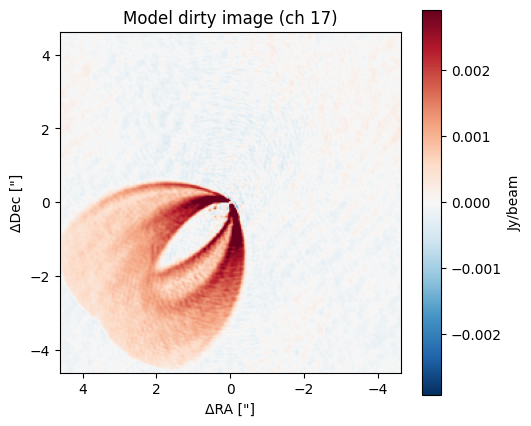

In [9]:
NPIX_D = 256
uu_c = (vis.uvw[:, 0] / lam[cc]).astype(np.float64)
vv_c = (vis.uvw[:, 1] / lam[cc]).astype(np.float64)
d_model = _dirty_image(uu_c, vv_c, vis_model[:, cc], NPIX_D, dpix_rad)

dpix_as_d = dpix_rad * (180/np.pi*3600)
extd = [NPIX_D/2*dpix_as_d, -NPIX_D/2*dpix_as_d, -NPIX_D/2*dpix_as_d, NPIX_D/2*dpix_as_d]
plt.figure(figsize=(5.5, 5))
vmax = np.nanpercentile(np.abs(d_model), 99.5)
plt.imshow(d_model, origin="lower", extent=extd, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
plt.colorbar(label="Jy/beam"); plt.title(f"Model dirty image (ch {cc})")
plt.xlabel("ΔRA [\"]"); plt.ylabel("ΔDec [\"]"); plt.show()

## 8. Model vs data — in the visibility plane

A subtlety that trips people up: the **magnitude** |V| of *noisy* data is positively
biased — `|signal + noise|` stays above zero even where the true signal vanishes — so a
raw mean-|V| profile sits on a noise floor and looks flat at long baselines. That is **not**
a model error (the reduced χ² below is ≈ 1); it is just why you must not compare a
mean-|V| data profile to a noiseless model.

The fix is to average the **complex** visibilities first: thermal noise is zero-mean, so it
averages down, leaving the signal. Left: the complex-averaged **Re⟨V⟩** profile for data vs
model (the dotted grey line is the misleading noise-biased mean-|V|). Middle/right: coarse
**complex-averaged** gridded |⟨V⟩| maps — with many visibilities per cell the data noise
beats down and the structure matches the model.

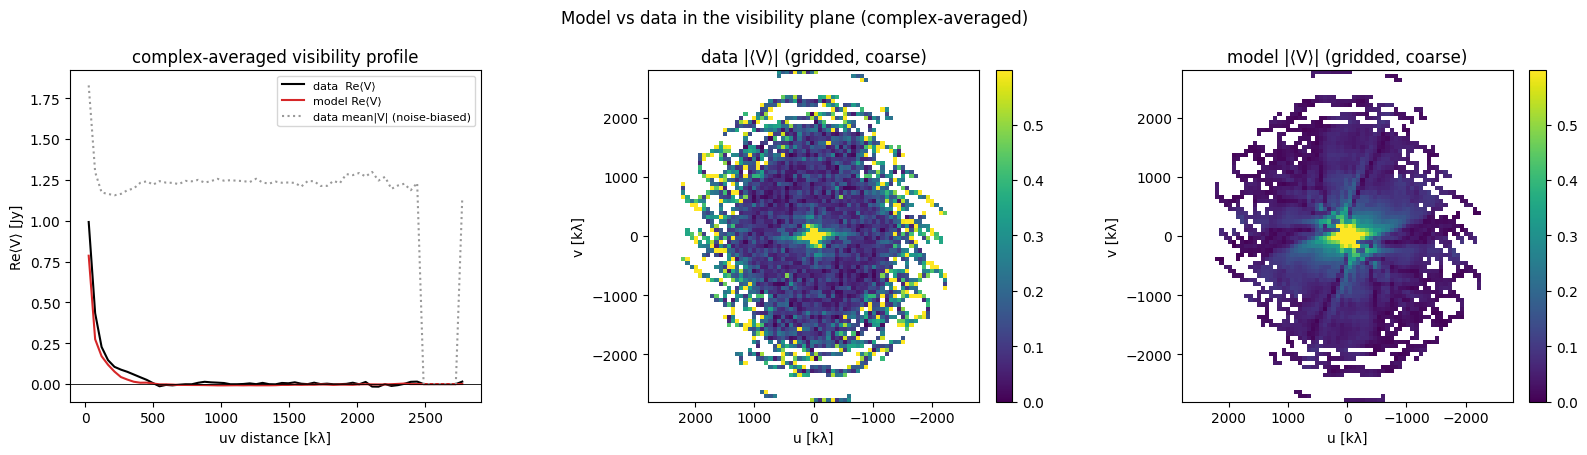

In [10]:
m = ~np.asarray(vis.flag)
uvd_k   = uvd[m] / 1e3
data_c  = np.asarray(vis.data)[m]           # complex
model_c = vis_model[m]
bins = np.linspace(0, uvd_k.max(), 60); bc = 0.5*(bins[:-1]+bins[1:])
bidx = np.clip(np.digitize(uvd_k, bins)-1, 0, len(bc)-1)

def cbin(x):                                 # complex mean per uv-distance bin
    re = np.bincount(bidx, weights=x.real, minlength=len(bc))
    im = np.bincount(bidx, weights=x.imag, minlength=len(bc))
    n  = np.bincount(bidx, minlength=len(bc))
    return (re + 1j*im) / np.maximum(n, 1)
Vd, Vm = cbin(data_c), cbin(model_c)
raw_absV = (np.bincount(bidx, weights=np.abs(data_c), minlength=len(bc))
            / np.maximum(np.bincount(bidx, minlength=len(bc)), 1))   # noise-biased

# coarse complex-averaged gridded |<V>| (many vis/cell -> low noise), line-centre channel
NG = 80
Be = np.linspace(-Bmax, Bmax, NG+1)
uu_cc = vis.uvw[:, 0] / lam[cc]; vv_cc = vis.uvw[:, 1] / lam[cc]
u2c = np.concatenate([uu_cc, -uu_cc]); v2c = np.concatenate([vv_cc, -vv_cc])
def cgrid(V):
    V2 = np.concatenate([V, np.conj(V)])
    re, _, _ = np.histogram2d(v2c, u2c, bins=[Be, Be], weights=V2.real)
    im, _, _ = np.histogram2d(v2c, u2c, bins=[Be, Be], weights=V2.imag)
    n,  _, _ = np.histogram2d(v2c, u2c, bins=[Be, Be])
    g = np.full(n.shape, np.nan); ok = n > 0
    g[ok] = np.abs((re[ok] + 1j*im[ok]) / n[ok]); return g
gd, gm = cgrid(np.asarray(vis.data)[:, cc]), cgrid(vis_model[:, cc])
gext = [Be[0]/1e3, Be[-1]/1e3, Be[0]/1e3, Be[-1]/1e3]
vmaxg = np.nanpercentile(gm, 99)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].plot(bc, Vd.real, "k-",  label="data  Re⟨V⟩")
ax[0].plot(bc, Vm.real, "C3-", label="model Re⟨V⟩")
ax[0].plot(bc, raw_absV, color="0.6", ls=":", label="data mean|V| (noise-biased)")
ax[0].axhline(0, color="k", lw=0.6)
ax[0].set(xlabel="uv distance [kλ]", ylabel="Re⟨V⟩ [Jy]",
          title="complex-averaged visibility profile"); ax[0].legend(fontsize=8)
for a, g, t in zip(ax[1:], [gd, gm], ["data |⟨V⟩| (gridded, coarse)", "model |⟨V⟩| (gridded, coarse)"]):
    h = a.imshow(g, origin="lower", extent=gext, cmap="viridis", vmin=0, vmax=vmaxg)
    a.set(xlabel="u [kλ]", ylabel="v [kλ]", title=t); a.invert_xaxis()
    plt.colorbar(h, ax=a, fraction=0.046, pad=0.04)
fig.suptitle("Model vs data in the visibility plane (complex-averaged)")
fig.tight_layout(); plt.show()

### Pointwise-average χ²

The uv-domain analogue of a per-pixel image χ²: weighted χ² summed over all
(row, channel) visibilities, divided by their number. Flagged samples (weight 0) drop out.
A **reduced χ² ≈ 1** (2 dof per complex visibility) means the model matches the data at
roughly the thermal-noise level.

In [11]:
w2 = np.asarray(vis.weight) * (~np.asarray(vis.flag))
obs_masked = VisibilityData(uvw=vis.uvw, freq=vis.freq, data=vis.data, weight=w2, flag=vis.flag)
chi2_total = float(chi2_vis(obs_masked, vis_model))
n_pts = int(np.sum(~np.asarray(vis.flag)))
print(f"total chi2             : {chi2_total:.4e}")
print(f"n unflagged visibilities: {n_pts}")
print(f"pointwise-average chi2 : {chi2_total/n_pts:.4f}  (per complex visibility)")
print(f"reduced chi2 (2 dof)   : {chi2_total/(2*n_pts):.4f}")

total chi2             : 2.8014e+07
n unflagged visibilities: 11992320
pointwise-average chi2 : 2.3360  (per complex visibility)
reduced chi2 (2 dof)   : 1.1680


## 9. Model vs data — dirty images (same code, same uv)

Finally the apples-to-apples comparison: the model and the data, each inverse-transformed
from the **same** MAPS uv sampling with the **same** `_dirty_image` routine. The residual
(data − model) should look noise-like if the model is good; a mirrored or rotated model
would show up immediately here.

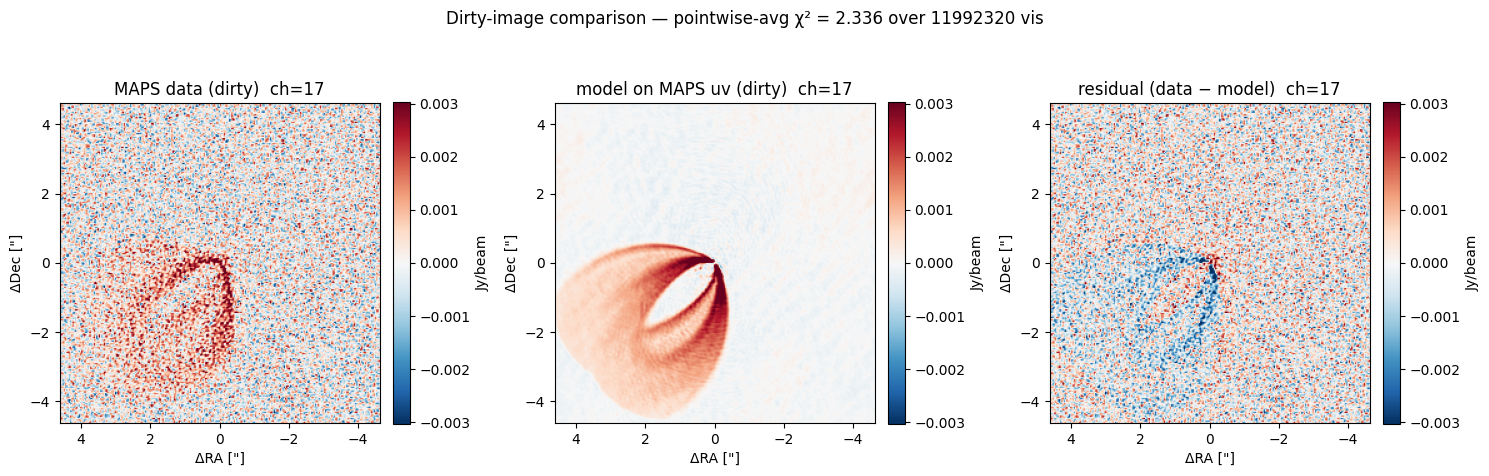

In [12]:
d_data  = _dirty_image(uu_c, vv_c, np.asarray(vis.data)[:, cc], NPIX_D, dpix_rad)
d_resid = _dirty_image(uu_c, vv_c, np.asarray(vis.data)[:, cc] - vis_model[:, cc], NPIX_D, dpix_rad)
vmax = np.nanpercentile(np.abs(d_data), 99.5)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im_, t in zip(ax, [d_data, d_model, d_resid],
                     ["MAPS data (dirty)", "model on MAPS uv (dirty)", "residual (data − model)"]):
    h = a.imshow(im_, origin="lower", extent=extd, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    a.set(xlabel="ΔRA [\"]", ylabel="ΔDec [\"]", title=f"{t}  ch={cc}")
    plt.colorbar(h, ax=a, fraction=0.046, pad=0.04, label="Jy/beam")
fig.suptitle(f"Dirty-image comparison — pointwise-avg χ² = {chi2_total/n_pts:.3f} over {n_pts} vis")
fig.tight_layout(); plt.show()

## Summary

- Loaded the MAPS CO 2–1 **uv data** and derived an imaging grid from the coverage.
- Visualised the **uv sampling** colour-coded by weight (via `hexbin`, no slow scatter).
- Rendered a **parametric HD 163296** model and pushed it through `image_to_vis` onto the
  real baselines (**GPU**, differentiable).
- Saw the model's **Fourier plane before/after sampling**, its **dirty image**, and a
  **model-vs-data** comparison in both the visibility plane and the image plane, with a
  **pointwise-average χ²**.

Because `image_to_vis` + `chi2_vis` are differentiable, this exact forward chain plugs
into gradient-based fitting (e.g. the neural-temperature model): swap the clean cube for a
model that depends on learnable parameters and backprop through the uv-domain χ².